# [Bonus Tasks](svm_segm.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [4]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [5]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [ ]:
step = 16

def create_data_matrix_sw(img):
    windows = skimage.util.view_as_windows(img, patch_sizes, step=step)
    return windows.reshape(-1, 32 * 32)


**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [8]:
def create_gt_labels_vector_sw(gt):
    windows = skimage.util.view_as_windows(gt, patch_sizes, step=step)
    center = windows[:, :, 8:24, 8:24]
    fraction = center.reshape(-1, 16 * 16).mean(axis=1)

    y = np.zeros(len(fraction))
    y[fraction > 0.5] = 1
    y[fraction == 0] = -1
    return y


**[Task 1.3.]()** Create the SVM classifier:

In [9]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [10]:
X33 = create_data_matrix_sw(plt.imread('data/NIH3T3/im/dna-33.png'))
X44 = create_data_matrix_sw(plt.imread('data/NIH3T3/im/dna-44.png'))

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [11]:
y33 = create_gt_labels_vector_sw(plt.imread('data/NIH3T3/gt/33.png') > 0)
y44 = create_gt_labels_vector_sw(plt.imread('data/NIH3T3/gt/44.png') > 0)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [12]:
X = np.concatenate([X33, X44])
Y = np.concatenate([y33, y44])
keep = Y != 0

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [13]:
clf2.fit(X[keep], Y[keep])

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [18]:
def predict_image(img):
    windows = skimage.util.view_as_windows(img, patch_sizes, step=step)
    gh, gw = windows.shape[:2]

    F = clf2.predict(windows.reshape(-1, 32 * 32))
    grid = (F == 1).reshape(gh, gw)
    big = np.repeat(np.repeat(grid, 16, axis=0), 16, axis=1)

    result = np.zeros(img.shape, dtype=bool)
    result[8 : 8 + gh * 16, 8 : 8 + gw * 16] = big
    return result

Test your implementation:

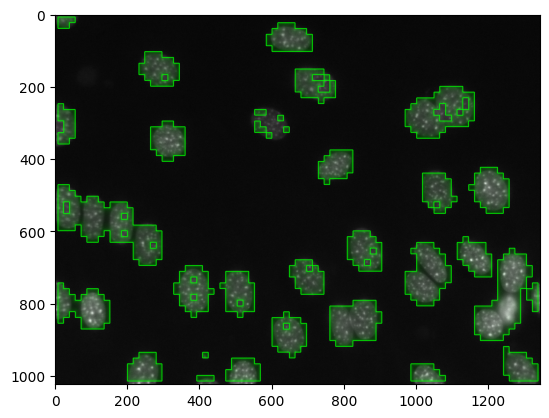

In [22]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.imshow(blend_result(img, seg))

**[Task 1.5.]()** Perform batch processing:

In [24]:
dices = []

def compute_dice(bin1, bin2):
    assert bin1.dtype == bool
    assert bin2.dtype == bool
    return 2 * (bin1 * bin2).sum() / (bin1.sum() + bin2.sum())


for i in [28, 29, 33, 44, 46, 49]:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png') > 0

    dice = compute_dice(predict_image(img), gt)
    print(i, dice)
    dices.append(dice)

print('Mittlerer Dice (Sliding Window):', np.mean(dices))


28 0.8003592682273475
29 0.7383164409331682
33 0.7721933855547508
44 0.8010301263136609
46 0.6724354579082271
49 0.7648782046085135
Mittlerer Dice (Sliding Window): 0.7582021472576113
